In [ ]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np
import pandas as pd

## Cargar y unir datos

In [ ]:
# Jupyter ejecuta el notebook desde su propia carpeta ("Calibraciones 04-11-2026"),
# así que las rutas relativas funcionan en cualquier clon del repositorio.
BASE = Path.cwd()

RUTA_REF = BASE / "17019_segundos_2026-11-06T10-31.dat"
RUTAS_DOMOS = {
    "Domo 1": [BASE / "Domo_1" / "20261104.csv"],
    "Domo 2": [BASE / "Domo_2" / "20261104.csv"],
    "Domo 3": [BASE / "Domo_3" / "20261104.csv"],
    # El RTC del Domo 4 perdió la hora: sus datos quedaron repartidos en 6 archivos.
    "Domo 4": [
        BASE / "Domo_4" / nombre
        for nombre in [
            "20260328.csv", "20260329.csv", "20260529.csv",
            "20261004.csv", "20261024.csv", "20261029.csv",
        ]
    ],
}

def leer_referencia(ruta):
    """Archivo TOA5 del Campbell CR300.
    Encabezado: fila 0 = metadatos, 1 = nombres, 2 = unidades, 3 = tipo de dato."""
    return pd.read_csv(
        ruta,
        skiprows=[0, 2, 3],
        na_values=["NAN"],
        parse_dates=["TIMESTAMP"],
        index_col="TIMESTAMP",
    )

def leer_domo(rutas):
    """Lee uno o varios CSV de un mismo domo y los une en una sola serie de tiempo."""
    partes = []
    for ruta in rutas:
        df = pd.read_csv(ruta, parse_dates=["Timestamp"])
        df["archivo"] = ruta.name  # de qué archivo viene cada fila (útil en el Domo 4)
        partes.append(df)
    df = pd.concat(partes, ignore_index=True)

    # Quita la fila que escribe el firmware al encender (todos los sensores en NaN).
    sensores = df.columns.difference(["Timestamp", "Timeon", "archivo"])
    df = df.dropna(subset=sensores, how="all")

    return df.set_index("Timestamp")

# Un DataFrame independiente por fuente, todos en un mismo diccionario.
datos = {"Referencia": leer_referencia(RUTA_REF)}
for nombre, rutas in RUTAS_DOMOS.items():
    datos[nombre] = leer_domo(rutas)

# Accesos directos (son los mismos objetos que hay en `datos`).
df_ref = datos["Referencia"]
df_d1 = datos["Domo 1"]
df_d2 = datos["Domo 2"]
df_d3 = datos["Domo 3"]
df_d4 = datos["Domo 4"]

# Resumen
for nombre, df in datos.items():
    print(f"{nombre:<10} {len(df):>6} filas  {df.index.min()} -> {df.index.max()}")

Referencia   4640 filas  2026-11-03 10:31:30 -> 2026-11-06 10:31:30
Domo 1      27053 filas  2026-11-04 10:02:42 -> 2026-11-04 17:51:47
Domo 2      27021 filas  2026-11-04 10:15:00 -> 2026-11-04 18:11:17
Domo 3      27092 filas  2026-11-04 10:02:27 -> 2026-11-04 17:51:26
Domo 4      32374 filas  2026-03-28 10:38:59 -> 2026-10-29 11:59:08


## Se corrigen las horas de las estaciones con problemas

In [20]:
# ---------------------------------------------------------------------------
# Configuración
# ---------------------------------------------------------------------------
FECHA_EXPERIMENTO = pd.Timestamp("2026-11-04")
BASES = ["Domo 1", "Domo 3"]  # domos con la hora correcta

# Qué parte de cada DataFrame se cuadra y con qué columna se compara.
# "archivo": None = todo el DataFrame; si no, solo las filas de ese archivo.
A_CUADRAR = {
    "Referencia": {"columna": "RH", "archivo": None, "paso": "10s"},  # registra cada 10 s
    "Domo 2": {"columna": "DHT_Hum", "archivo": None, "paso": "1s"},
    # El RTC del Domo 4 perdió la hora: solo este archivo corresponde al experimento.
    "Domo 4": {"columna": "DHT_Hum", "archivo": "20261004.csv", "paso": "1s"},
}
COLUMNA_BASE = "DHT_Hum"
RANGO_BUSQUEDA = pd.Timedelta(minutes=40)  # ± alrededor de la estimación inicial


# ---------------------------------------------------------------------------
# Funciones
# ---------------------------------------------------------------------------
def regularizar(serie, paso):
    """Promedia en una grilla regular y rellena huecos cortos."""
    serie = serie[~serie.index.duplicated()].sort_index()
    return serie.resample(paso).mean().interpolate(limit=6, limit_area="inside")


def buscar_desfase(serie, base, centro, rango, paso):
    """Corrimiento en [centro - rango, centro + rango] que maximiza la correlación."""
    s = regularizar(serie, paso)
    b = regularizar(base, paso)
    paso = pd.Timedelta(paso)
    centro = centro.round(paso)  # el centro debe caer en la grilla
    n = int(rango / paso)
    candidatos = [centro + k * paso for k in range(-n, n + 1)]
    r = [s.set_axis(s.index + c).reindex(b.index).corr(b) for c in candidatos]
    i = int(np.nanargmax(r))
    return candidatos[i], r[i]


def estimar_desfase(serie, base, paso):
    """Búsqueda gruesa (10 s, ±40 min) y fina (paso, ±20 s)."""
    # Estimación inicial: misma hora del día, corrigiendo solo la fecha.
    centro = FECHA_EXPERIMENTO - serie.index[0].normalize()
    desfase, r = buscar_desfase(serie, base, centro, RANGO_BUSQUEDA, "10s")
    if pd.Timedelta(paso) < pd.Timedelta("10s"):
        desfase, r = buscar_desfase(serie, base, desfase, pd.Timedelta("20s"), paso)
    return desfase, r


def formato(td):
    signo = "-" if td < pd.Timedelta(0) else "+"
    td = abs(td)
    seg = int(td.total_seconds()) % 86400
    dias = f"{td.days} d " if td.days else ""
    return f"{signo}{dias}{seg // 3600:02d}:{seg // 60 % 60:02d}:{seg % 60:02d}"


# ---------------------------------------------------------------------------
# Estimación
# ---------------------------------------------------------------------------
resultados = []
for nombre, cfg in A_CUADRAR.items():
    df = datos[nombre]
    if cfg["archivo"] is not None:
        df = df[df["archivo"] == cfg["archivo"]]
    serie = df[cfg["columna"]]
    if nombre == "Referencia":
        serie = serie.loc[FECHA_EXPERIMENTO.strftime("%Y-%m-%d")]

    for base in BASES:
        desfase, r = estimar_desfase(serie, datos[base][COLUMNA_BASE], cfg["paso"])
        resultados.append({"estacion": nombre, "base": base, "desfase": desfase, "r": r})

resultados = pd.DataFrame(resultados)

# Desfase final: promedio de lo obtenido contra Domo 1 y Domo 3, redondeado a 1 s.
DESFASES = resultados.groupby("estacion", sort=False)["desfase"].mean().dt.round("1s").to_dict()

print(resultados.assign(desfase=resultados["desfase"].map(formato), r=resultados["r"].round(4))
      .to_string(index=False))
print("\nDesfase aplicado (se suma a la hora registrada):")
for nombre, d in DESFASES.items():
    print(f"  {nombre:<10} {formato(d)}")


# ---------------------------------------------------------------------------
# Aplicación: nuevo diccionario `datos_sync`; `datos` queda intacto.
# La hora original se conserva en la columna "Hora_RTC".
# ---------------------------------------------------------------------------
datos_sync = {}
for nombre, df in datos.items():
    df = df.copy()
    df.insert(0, "Hora_RTC", df.index)
    if nombre in DESFASES:
        archivo = A_CUADRAR[nombre]["archivo"]
        filas = np.ones(len(df), bool) if archivo is None else (df["archivo"] == archivo).to_numpy()
        nuevo = df.index.to_series()
        nuevo[filas] = nuevo[filas] + DESFASES[nombre]
        df.index = pd.DatetimeIndex(nuevo, name=df.index.name)
    datos_sync[nombre] = df

df_ref, df_d1, df_d2, df_d3, df_d4 = (datos_sync[k] for k in
                                      ["Referencia", "Domo 1", "Domo 2", "Domo 3", "Domo 4"])


  estacion   base        desfase      r
Referencia Domo 1      +00:00:00 0.9915
Referencia Domo 3      +00:00:00 0.9950
    Domo 2 Domo 1      -00:19:35 0.9994
    Domo 2 Domo 3      -00:19:34 0.9980
    Domo 4 Domo 1 +31 d 00:05:57 0.9995
    Domo 4 Domo 3 +31 d 00:05:57 0.9992

Desfase aplicado (se suma a la hora registrada):
  Referencia +00:00:00
  Domo 2     -00:19:34
  Domo 4     +31 d 00:05:57


## Graficos Exploratorios

In [25]:
# ---------------------------------------------------------------------------
# Datos del día del experimento (hora ya cuadrada en `datos_sync`)
# ---------------------------------------------------------------------------
FECHA = "2026-11-04"
ESTACIONES = ["Domo 1", "Domo 2", "Domo 3", "Domo 4"]

# Para el Domo 4 esto deja solo las filas del experimento: sus otros archivos
# (marzo-octubre) quedan fuera.
exp = {nombre: df.loc[FECHA].sort_index() for nombre, df in datos_sync.items()}

# El SHT40 entrega valores en los extremos de su escala cuando falla la lectura
# (-45 / -37.7 / 130 °C, 0 / 100 %). Se marcan como NaN para no graficarlos.
for nombre in ESTACIONES:
    df = exp[nombre]
    invalido = ~(df["SHT_Temp"].between(-40, 125, inclusive="neither")
                 & df["SHT_Hum"].between(0, 100, inclusive="neither"))
    exp[nombre] = df.assign(
        SHT_Temp=df["SHT_Temp"].mask(invalido),
        SHT_Hum=df["SHT_Hum"].mask(invalido),
    )

COLORES = {"Domo 1": "#2a78d6", "Domo 2": "#eb6834", "Domo 3": "#1baf7a", "Domo 4": "#eda100"}
COLOR_REF = "#3d3d3a"
COLOR_GRILLA = "#e4e3df"


def graficar_vs_referencia(exp, col_domo, col_ref, etiqueta, titulo, margen, sensor="SHT40"):
    """Un panel por estación: SHT40 (color) vs. referencia (línea discontinua).

    La escala Y es la misma en todos los paneles y se ajusta al rango de la
    referencia ± `margen`; los puntos que quedan fuera se cuentan en el panel.
    """
    ref = exp["Referencia"][col_ref]
    y_min, y_max = ref.min() - margen, ref.max() + margen

    fig, ejes = plt.subplots(2, 2, figsize=(13, 7), sharex=True, sharey=True,
                             layout="constrained")
    for ax, nombre in zip(ejes.flat, ESTACIONES):
        serie = exp[nombre][col_domo]
        ax.plot(serie.index, serie, lw=1.2, color=COLORES[nombre], label=f"{nombre} ({sensor})")
        ax.plot(ref.index, ref, lw=1.5, ls="--", color=COLOR_REF, label="Referencia")

        fuera = int(((serie < y_min) | (serie > y_max)).sum())
        validos = int(serie.notna().sum())
        nota = f"{validos} lecturas válidas"
        if fuera:
            nota += f"\n{fuera} fuera de escala"
        ax.text(0.99, 0.03, nota, transform=ax.transAxes, ha="right", va="bottom",
                fontsize=8, color="#5f5e5a")

        ax.set_title(nombre, loc="left", fontsize=11)
        ax.legend(loc="upper left", frameon=False, fontsize=8)
        ax.grid(True, color=COLOR_GRILLA, lw=0.6)
        ax.spines[["top", "right"]].set_visible(False)

    ejes[0, 0].set_ylim(y_min, y_max)
    for ax in ejes[:, 0]:
        ax.set_ylabel(etiqueta)
    for ax in ejes[-1]:
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
        ax.set_xlabel(f"Hora ({FECHA})")
    fig.suptitle(titulo)
    return fig, ejes

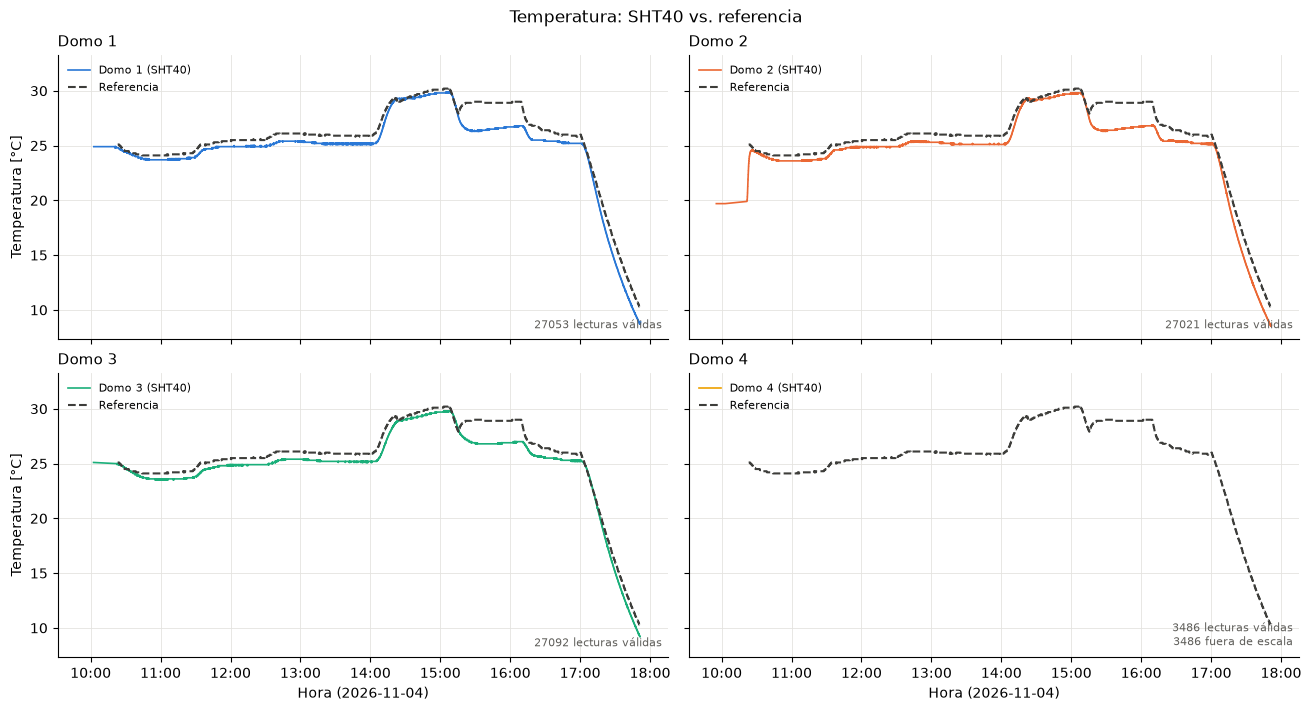

In [23]:
fig_t, _ = graficar_vs_referencia(exp, "SHT_Temp", "AirT_C", "Temperatura [°C]",
                                  "Temperatura: SHT40 vs. referencia", margen=3)
plt.show()

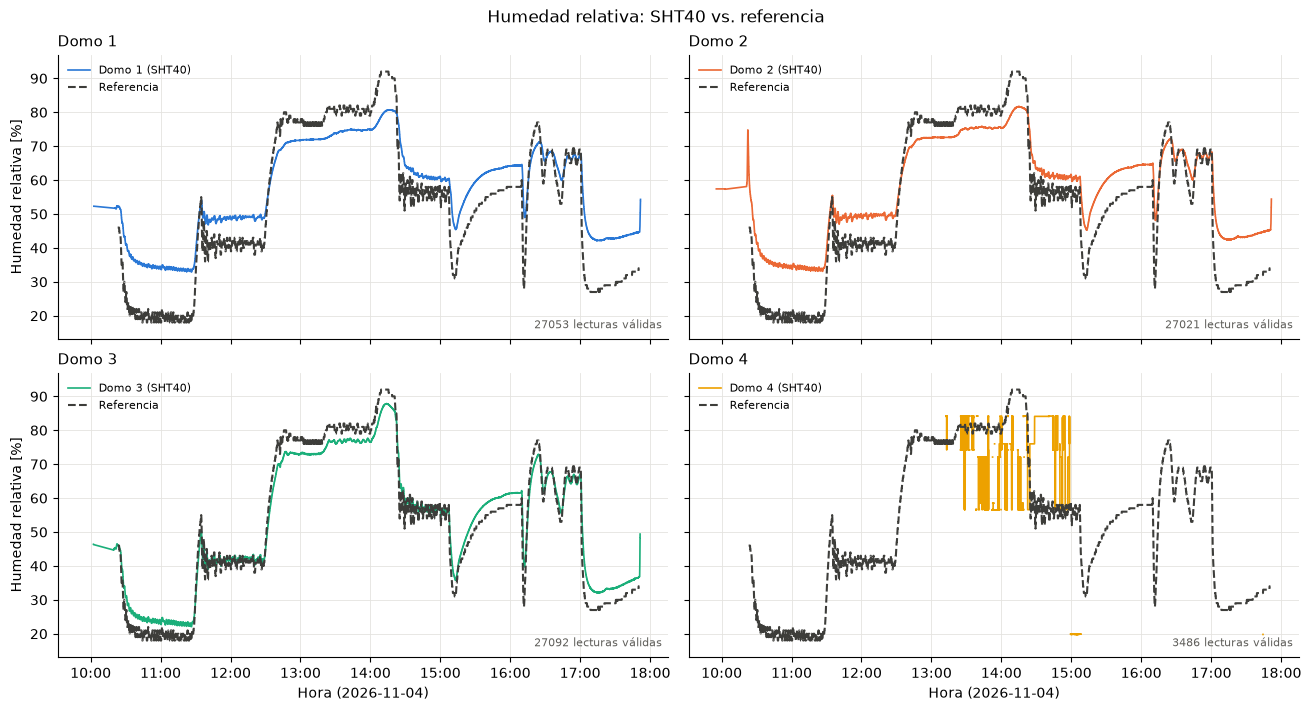

In [24]:
fig_h, _ = graficar_vs_referencia(exp, "SHT_Hum", "RH", "Humedad relativa [%]",
                                  "Humedad relativa: SHT40 vs. referencia", margen=5)
plt.show()

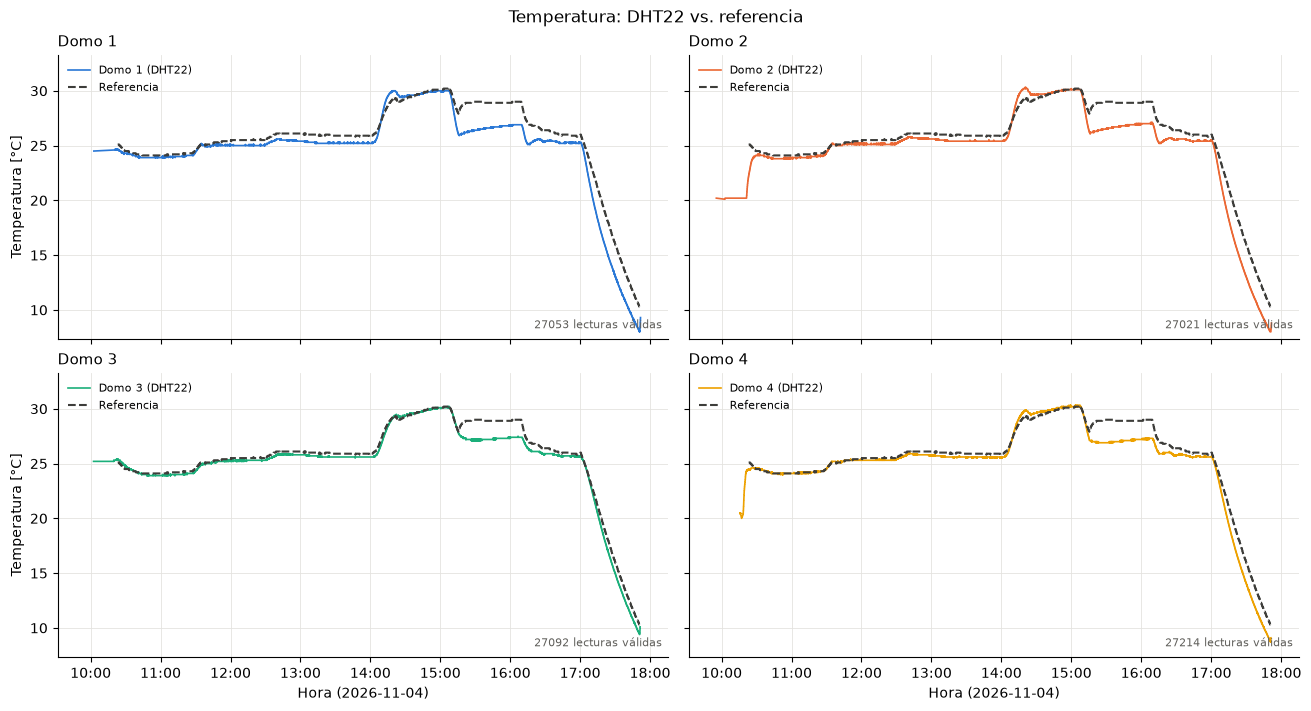

In [26]:
fig_dht_t, _ = graficar_vs_referencia(exp, "DHT_Temp", "AirT_C", "Temperatura [°C]",
                                      "Temperatura: DHT22 vs. referencia",
                                      margen=3, sensor="DHT22")
plt.show()

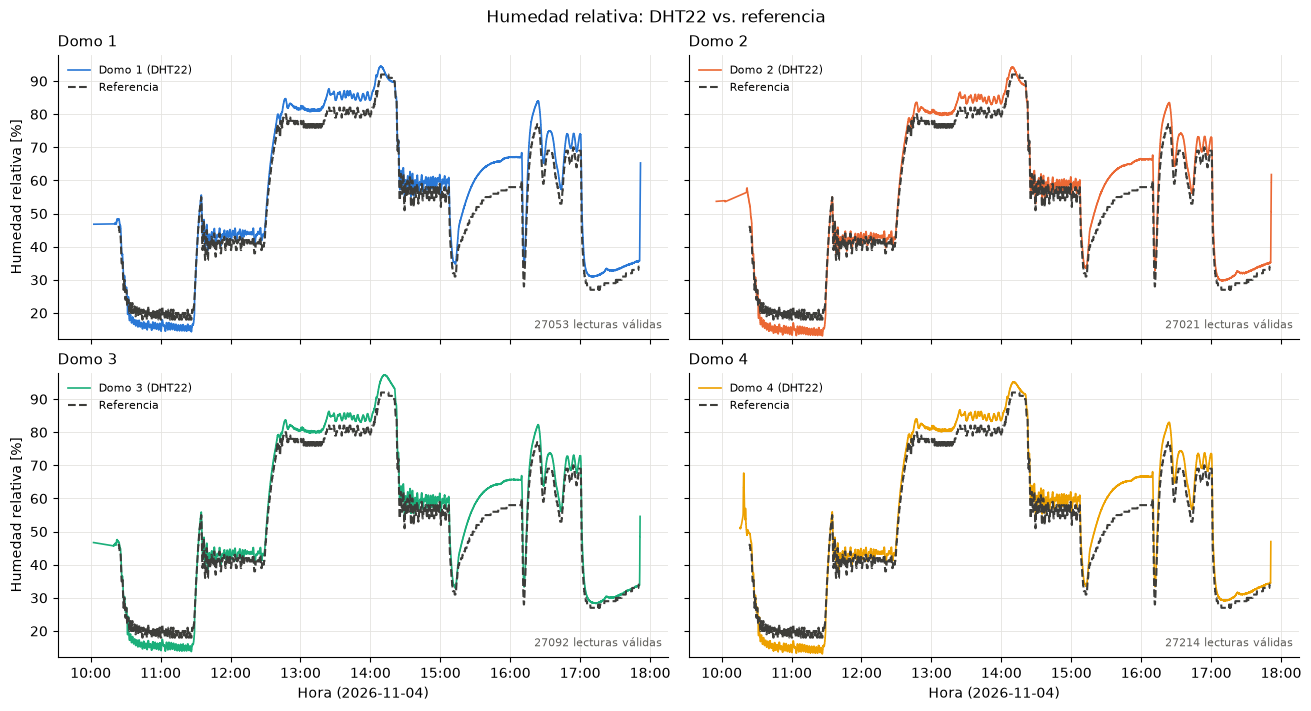

In [27]:
fig_dht_h, _ = graficar_vs_referencia(exp, "DHT_Hum", "RH", "Humedad relativa [%]",
                                      "Humedad relativa: DHT22 vs. referencia",
                                      margen=6, sensor="DHT22")
plt.show()

## Cálculo de Error por sensor

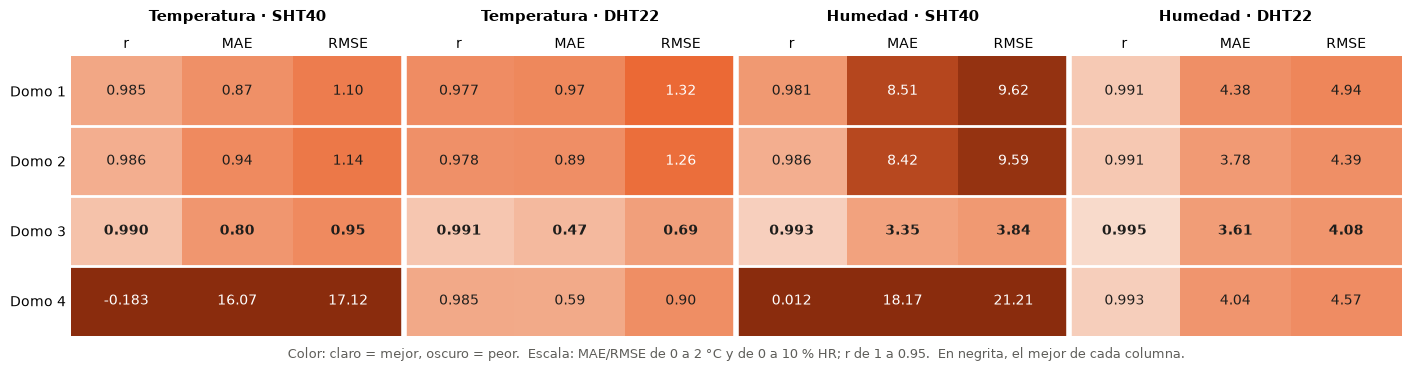

In [29]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

# ---------------------------------------------------------------------------
# Escala de color: 0 = bueno (claro), 1 = malo (oscuro).
# MAE y RMSE: 0 -> límite de la tabla (sobre el límite queda en el color más oscuro).
# r: 1 -> R_MALO (bajo R_MALO queda en el color más oscuro).
# ---------------------------------------------------------------------------
LIMITE_ERROR = {"Temperatura [°C]": 2.0, "Humedad [%]": 10.0}
R_MALO = 0.95
CMAP_ERROR = LinearSegmentedColormap.from_list("error", ["#fbf3ee", "#f2a27e", "#eb6834", "#8a2c0d"])

VARIABLES = ["Temperatura [°C]", "Humedad [%]"]
SENSORES = ["SHT40", "DHT22"]
METRICAS = ["r", "MAE", "RMSE"]


def nivel_de_error(metrica, variable, valor):
    if metrica == "r":
        return np.clip((1 - valor) / (1 - R_MALO), 0, 1)
    return np.clip(valor / LIMITE_ERROR[variable], 0, 1)


def graficar_grilla(tabla):
    columnas = [(v, s, m) for v in VARIABLES for s in SENSORES for m in METRICAS]
    t = tabla.set_index(["estacion", "variable", "sensor"])

    valores = np.array([[t.loc[(e, v, s), m] for v, s, m in columnas] for e in ESTACIONES])
    niveles = np.array([[nivel_de_error(m, v, t.loc[(e, v, s), m]) for v, s, m in columnas]
                        for e in ESTACIONES])

    fig, ax = plt.subplots(figsize=(14, 3.6), layout="constrained")
    ax.imshow(niveles, cmap=CMAP_ERROR, vmin=0, vmax=1, aspect="auto")

    # Valor en cada celda; se destaca en negrita el mejor de cada columna.
    for j, (v, s, m) in enumerate(columnas):
        col = valores[:, j]
        mejor = np.nanargmax(col) if m == "r" else np.nanargmin(col)
        for i in range(len(ESTACIONES)):
            texto = f"{col[i]:.3f}" if m == "r" else f"{col[i]:.2f}"
            ax.text(j, i, texto, ha="center", va="center", fontsize=10,
                    fontweight="bold" if i == mejor else "normal",
                    color="white" if niveles[i, j] > 0.6 else "#1f1e1c")

    # Ejes y encabezados
    ax.set_yticks(range(len(ESTACIONES)), ESTACIONES)
    ax.set_xticks(range(len(columnas)), [m for _, _, m in columnas])
    ax.xaxis.tick_top()
    ax.tick_params(length=0)
    for k in range(0, len(columnas), len(METRICAS)):
        v, s, _ = columnas[k]
        ax.text(k + 1, -0.95, f"{v.split(' ')[0]} · {s}", ha="center", va="bottom",
                fontsize=11, fontweight="bold")
        if k:
            ax.axvline(k - 0.5, color="white", lw=4)  # separa los grupos
    for i in range(1, len(ESTACIONES)):
        ax.axhline(i - 0.5, color="white", lw=2)
    ax.spines[:].set_visible(False)

    ax.set_xlabel(
        f"Color: claro = mejor, oscuro = peor.  Escala: MAE/RMSE de 0 a "
        f"{LIMITE_ERROR['Temperatura [°C]']:g} °C y de 0 a {LIMITE_ERROR['Humedad [%]']:g} % HR; "
        f"r de 1 a {R_MALO}.  En negrita, el mejor de cada columna.",
        fontsize=9, color="#5f5e5a", labelpad=8,
    )
    return fig, ax


fig_grilla, _ = graficar_grilla(tabla_metricas)
plt.show()


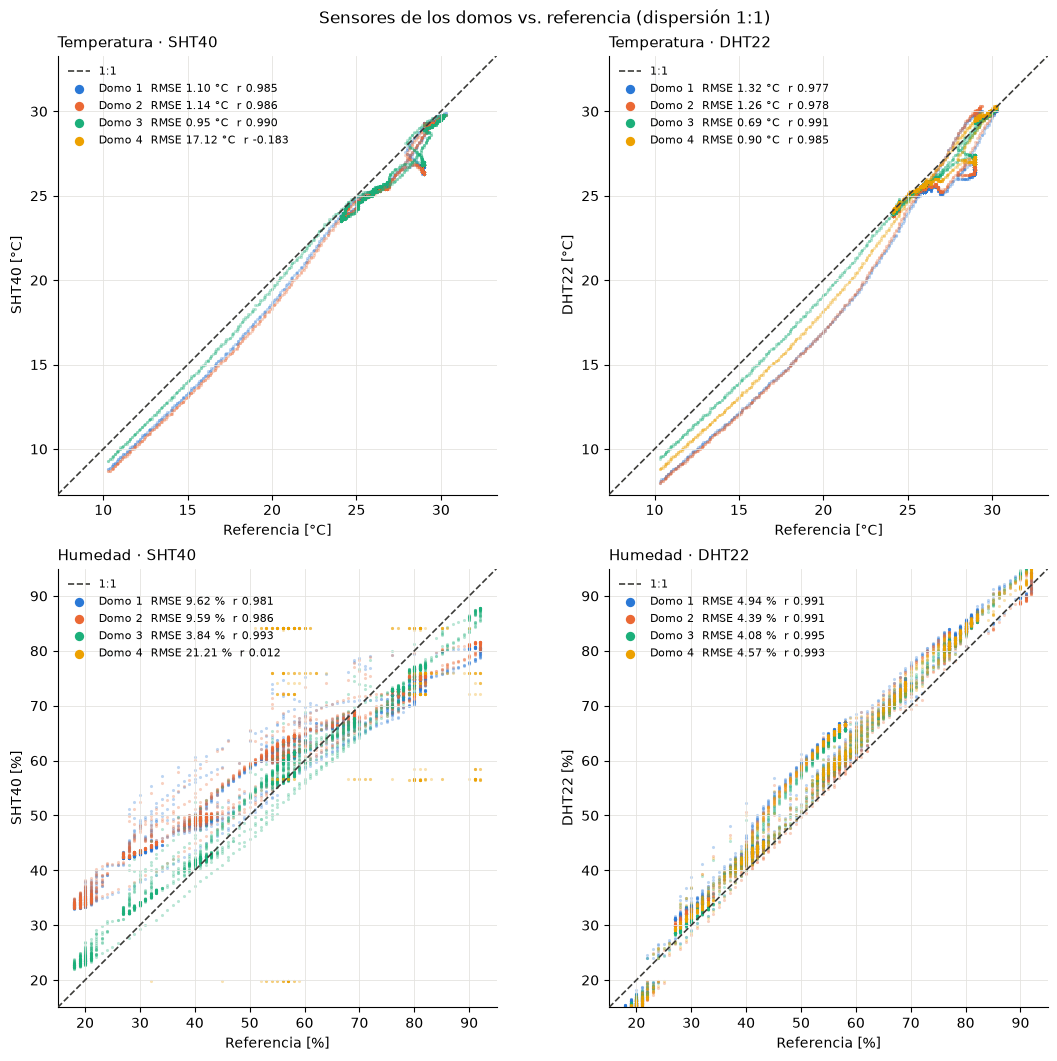

In [30]:
def graficar_dispersion_1a1(pares, tabla):
    """Una dispersión por variable y sensor; las 4 estaciones superpuestas.

    Línea discontinua = 1:1 (domo igual a referencia). Sobre ella el sensor
    sobrestima; bajo ella, subestima.
    """
    fig, ejes = plt.subplots(len(VARIABLES), len(SENSORES), figsize=(11, 10.5),
                             layout="constrained")
    t = tabla.set_index(["estacion", "variable", "sensor"])

    for i, variable in enumerate(VARIABLES):
        # Mismos límites para ambos sensores de una variable, según la referencia.
        ref_todas = pd.concat([pares[(e, s, variable)]["ref"] for e in ESTACIONES for s in SENSORES])
        lim = (ref_todas.min() - 3, ref_todas.max() + 3)
        unidad = variable.split("[")[1].rstrip("]")

        for j, sensor in enumerate(SENSORES):
            ax = ejes[i, j]
            ax.plot(lim, lim, ls="--", lw=1.2, color=COLOR_REF, label="1:1", zorder=3)
            for nombre in ESTACIONES:
                p = pares[(nombre, sensor, variable)]
                m = t.loc[(nombre, variable, sensor)]
                ax.scatter(p["ref"], p["domo"], s=5, alpha=0.3, linewidths=0,
                           color=COLORES[nombre], rasterized=True,
                           label=f"{nombre}  RMSE {m['RMSE']:.2f} {unidad}  r {m['r']:.3f}")

            ax.set_xlim(lim)
            ax.set_ylim(lim)
            ax.set_aspect("equal")
            ax.grid(True, color=COLOR_GRILLA, lw=0.6)
            ax.spines[["top", "right"]].set_visible(False)
            ax.set_title(f"{variable.split(' ')[0]} · {sensor}", loc="left", fontsize=11)
            ax.set_xlabel(f"Referencia [{unidad}]")
            ax.set_ylabel(f"{sensor} [{unidad}]")
            leyenda = ax.legend(loc="upper left", frameon=False, fontsize=8, markerscale=3)
            for h in leyenda.legend_handles:
                h.set_alpha(1)

    fig.suptitle("Sensores de los domos vs. referencia (dispersión 1:1)")
    return fig, ejes


fig_disp, _ = graficar_dispersion_1a1(pares, tabla_metricas)
plt.show()
